In [1]:
# Cell 1 — Import Libraries
import os
import json
import glob
import yaml
from pathlib import Path
from collections import defaultdict
import matplotlib.pyplot as plt

In [2]:
# Cell 2 — Define Paths
dataset_path = "../datasets"

datasets = {
    "Garbage_Detection": "yolo",
    "Pakistan_Garbage": "yolo",
    "TACO": "coco",
    "pLitterStreet": "coco"
}

print("✅ Paths defined successfully")
print(f"📁 Dataset path: {os.path.abspath(dataset_path)}")

✅ Paths defined successfully
📁 Dataset path: d:\Master_Waste_Dataset\datasets


In [3]:
# Cell 3 — Count Images per Dataset
print("📸 عدد الصور في كل Dataset:\n")

total_images = 0
for dataset_name in datasets:
    dataset_dir = os.path.join(dataset_path, dataset_name)
    
    images = glob.glob(f"{dataset_dir}/**/*.jpg", recursive=True) + \
             glob.glob(f"{dataset_dir}/**/*.png", recursive=True) + \
             glob.glob(f"{dataset_dir}/**/*.jpeg", recursive=True)
    
    total_images += len(images)
    print(f"  {dataset_name}: {len(images)} صورة")

print(f"\n  📊 الإجمالي: {total_images} صورة")

📸 عدد الصور في كل Dataset:

  Garbage_Detection: 10464 صورة
  Pakistan_Garbage: 12267 صورة
  TACO: 1500 صورة
  pLitterStreet: 15138 صورة

  📊 الإجمالي: 39369 صورة


In [4]:
# Cell 4 — Define Final Class Mapping
CLASS_MAPPING = {
    # Plastic
    'PLASTIC': 'Plastic', 'Plastic': 'Plastic',
    'plastic bag': 'Plastic', 'sachet': 'Plastic',
    'straw': 'Plastic', 'Plastic film': 'Plastic',
    'Clear plastic bottle': 'Plastic', 'Other plastic bottle': 'Plastic',
    'Plastic bottle cap': 'Plastic', 'Plastic straw': 'Plastic',
    'Disposable plastic cup': 'Plastic', 'Single-use carrier bag': 'Plastic',
    'Polypropylene bag': 'Plastic', 'Crisp packet': 'Plastic',
    'Spread tub': 'Plastic', 'Tupperware': 'Plastic',
    'Disposable food container': 'Plastic', 'Foam food container': 'Plastic',
    'Foam cup': 'Plastic', 'Other plastic container': 'Plastic',
    'Plastic glooves': 'Plastic', 'Plastic utensils': 'Plastic',
    'Squeezable tube': 'Plastic', 'Plastic lid': 'Plastic',
    'Six pack rings': 'Plastic', 'Styrofoam piece': 'Plastic',
    'Other plastic cup': 'Plastic', 'Other plastic wrapper': 'Plastic',
    'Other plastic': 'Plastic', 'Carded blister pack': 'Plastic',
    'Garbage Bag': 'Plastic', 'Garbage bag': 'Plastic',

    # Glass
    'GLASS': 'Glass', 'Glass': 'Glass',
    'Glass bottle': 'Glass', 'Broken glass': 'Glass',
    'Glass jar': 'Glass', 'Glass cup': 'Glass',

    # Metal
    'METAL': 'Metal', 'Metal': 'Metal',
    'Drink can': 'Metal', 'Food Can': 'Metal',
    'Aerosol': 'Metal', 'Scrap metal': 'Metal',
    'Metal bottle cap': 'Metal', 'Metal lid': 'Metal',
    'Pop tab': 'Metal', 'Aluminium foil': 'Metal',
    'Aluminium blister pack': 'Metal',

    # Paper
    'PAPER': 'Paper', 'Paper': 'Paper',
    'CARDBOARD': 'Paper', 'Paper cup': 'Paper',
    'Paper bag': 'Paper', 'Paper straw': 'Paper',
    'Normal paper': 'Paper', 'Magazine paper': 'Paper',
    'Tissues': 'Paper', 'Wrapping paper': 'Paper',
    'Corrugated carton': 'Paper', 'Other carton': 'Paper',
    'Egg carton': 'Paper', 'Drink carton': 'Paper',
    'Meal carton': 'Paper', 'Pizza box': 'Paper',
    'Toilet tube': 'Paper', 'Plastified paper bag': 'Paper',

    # Organic
    'Organic': 'Organic', 'Animal Waste': 'Organic',
    'Food waste': 'Organic',

    # Non-Recyclable
    'Cigarette': 'Non-Recyclable', 'Rope & strings': 'Non-Recyclable',
    'Shoe': 'Non-Recyclable', 'Battery': 'Non-Recyclable',
}

# Classes هتتشال خالص
REMOVE_CLASSES = [
    'BIODEGRADABLE', 'litter', 'pile', 'Pile', 'waste',
    'Unlabeled litter', 'trash bin', 'Trash bin',
    'face mask', 'Face mask', 'rope',
    'Construction Waste', 'bottle', 'cup'
]

FINAL_CLASSES = ['Plastic', 'Glass', 'Metal', 'Paper', 'Organic', 'Non-Recyclable']

print("✅ Class Mapping defined successfully")
print(f"📊 عدد الـ Classes في الـ Mapping: {len(CLASS_MAPPING)}")
print(f"❌ عدد الـ Classes اللي هتتشال: {len(REMOVE_CLASSES)}")
print(f"\n🎯 الـ Final Classes:")
for i, cls in enumerate(FINAL_CLASSES):
    print(f"  {i}: {cls}")

✅ Class Mapping defined successfully
📊 عدد الـ Classes في الـ Mapping: 74
❌ عدد الـ Classes اللي هتتشال: 14

🎯 الـ Final Classes:
  0: Plastic
  1: Glass
  2: Metal
  3: Paper
  4: Organic
  5: Non-Recyclable


In [5]:
# Cell 5 — Count Objects per Final Class
print("📊 عدد الـ Objects في كل Class بعد الـ Mapping:\n")

final_counts = defaultdict(int)
removed_counts = defaultdict(int)

for dataset_name, fmt in datasets.items():
    dataset_dir = os.path.join(dataset_path, dataset_name)
    
    # YOLO Format
    if fmt == "yolo":
        yaml_files = glob.glob(f"{dataset_dir}/**/*.yaml", recursive=True)
        if not yaml_files:
            continue
        with open(yaml_files[0], 'r') as f:
            yaml_data = yaml.safe_load(f)
        class_names = yaml_data.get('names', [])
        if isinstance(class_names, dict):
            class_names = [class_names[i] for i in sorted(class_names.keys())]
        
        txt_files = glob.glob(f"{dataset_dir}/**/*.txt", recursive=True)
        for txt_file in txt_files:
            with open(txt_file, 'r') as f:
                lines = f.readlines()
            for line in lines:
                line = line.strip()
                if not line or line.startswith('#'):
                    continue
                parts = line.split()
                if len(parts) < 5:
                    continue
                try:
                    class_id = int(parts[0])
                except ValueError:
                    continue
                if class_id >= len(class_names):
                    continue
                class_name = class_names[class_id]
                if class_name in CLASS_MAPPING:
                    final_counts[CLASS_MAPPING[class_name]] += 1
                elif class_name in REMOVE_CLASSES:
                    removed_counts[class_name] += 1

    # COCO Format
    elif fmt == "coco":
        json_files = glob.glob(f"{dataset_dir}/**/*.json", recursive=True)
        for json_file in json_files:
            with open(json_file, 'r') as f:
                data = json.load(f)
            if 'categories' not in data or 'annotations' not in data:
                continue
            categories = {cat['id']: cat['name'] for cat in data['categories']}
            for ann in data['annotations']:
                class_name = categories.get(ann['category_id'], '')
                if class_name in CLASS_MAPPING:
                    final_counts[CLASS_MAPPING[class_name]] += 1
                elif class_name in REMOVE_CLASSES:
                    removed_counts[class_name] += 1

total_kept = sum(final_counts.values())
total_removed = sum(removed_counts.values())

print("✅ Objects هتتبقى:")
for cls in FINAL_CLASSES:
    count = final_counts[cls]
    bar = "█" * (count // 5000)
    print(f"  {cls:<20} {count:>8} {bar}")

print(f"\n  📊 الإجمالي: {total_kept}")

print("\n❌ Objects هتتشال:")
for cls, count in sorted(removed_counts.items(), key=lambda x: -x[1]):
    print(f"  {cls:<30} {count:>8}")

print(f"\n  📊 الإجمالي: {total_removed}")

📊 عدد الـ Objects في كل Class بعد الـ Mapping:

✅ Objects هتتبقى:
  Plastic                128001 █████████████████████████
  Glass                   11458 ██
  Metal                   10245 ██
  Paper                   12789 ██
  Organic                  6138 █
  Non-Recyclable           1410 

  📊 الإجمالي: 170041

❌ Objects هتتشال:
  litter                           116566
  BIODEGRADABLE                     45407
  bottle                             3792
  waste                              2744
  rope                               2592
  pile                               2590
  Face mask                          2087
  cup                                1870
  Construction Waste                 1850
  Pile                               1828
  face mask                          1644
  trash bin                          1536
  Unlabeled litter                   1034
  Trash bin                           932

  📊 الإجمالي: 186472


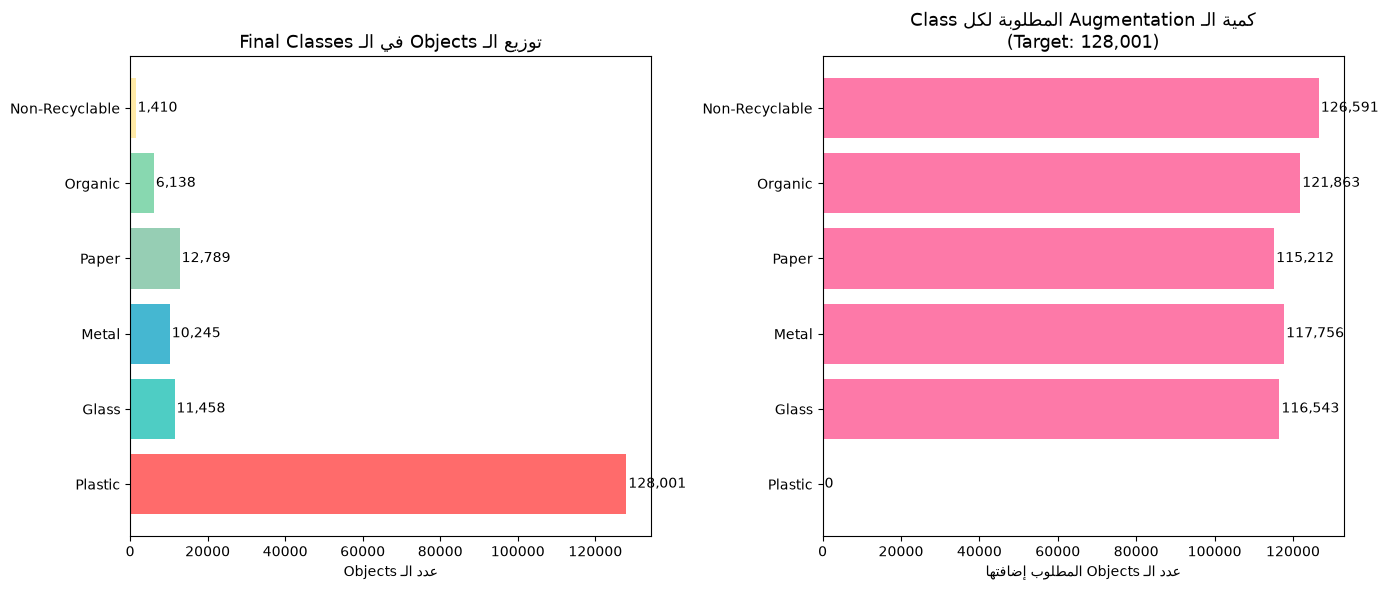


🎯 Target لكل Class: 128,001

📊 الـ Augmentation المطلوبة:
  Plastic              +0
  Glass                +116,543
  Metal                +117,756
  Paper                +115,212
  Organic              +121,863
  Non-Recyclable       +126,591


In [6]:
# Cell 6 — Visualize Class Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Before (كل الداتا)
all_counts = {cls: final_counts[cls] for cls in FINAL_CLASSES}
removed_total = sum(removed_counts.values())

# Chart 1 — Final Classes Distribution
classes = FINAL_CLASSES
counts = [final_counts[cls] for cls in classes]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#88D8B0', '#FFEAA7']

axes[0].barh(classes, counts, color=colors)
axes[0].set_title('توزيع الـ Objects في الـ Final Classes', fontsize=13)
axes[0].set_xlabel('عدد الـ Objects')
for i, (cls, count) in enumerate(zip(classes, counts)):
    axes[0].text(count + 500, i, f'{count:,}', va='center', fontsize=10)

# Chart 2 — كمية الـ Augmentation المطلوبة
target = max(counts)
needed = [target - c for c in counts]

axes[1].barh(classes, needed, color='#FD79A8')
axes[1].set_title(f'كمية الـ Augmentation المطلوبة لكل Class\n(Target: {target:,})', fontsize=13)
axes[1].set_xlabel('عدد الـ Objects المطلوب إضافتها')
for i, (cls, n) in enumerate(zip(classes, needed)):
    axes[1].text(n + 500, i, f'{n:,}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('../notebooks/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n🎯 Target لكل Class: {target:,}")
print("\n📊 الـ Augmentation المطلوبة:")
for cls, n in zip(classes, needed):
    print(f"  {cls:<20} +{n:,}")